## 1. Setup: check the GPU and import libraries




In [1]:
# Libraries for deep learning, data handling, metrics, and plotting
import os, json, random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Use the GPU if available (Colab: Runtime > Change runtime type > T4 GPU)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"   # mixed precision: faster training on GPU
print("Device:", DEVICE)

Device: cuda


## 2. Fix random seeds so results are reproducible

In [2]:
# Same seed = same data split and very similar results every run
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.makedirs("results", exist_ok=True)   # folder for charts and metrics

## 3. Download the Oxford-IIIT Pet dataset (37 cat and dog breeds)

In [3]:
# torchvision downloads the dataset and its official "trainval" and "test" splits
DATA_DIR = "data"
trainval_raw = datasets.OxfordIIITPet(DATA_DIR, split="trainval", target_types="category", download=True)
test_raw = datasets.OxfordIIITPet(DATA_DIR, split="test", target_types="category", download=True)

CLASSES = trainval_raw.classes          # the 37 breed names, in label order
print("Train+val images:", len(trainval_raw))
print("Test images:", len(test_raw))
print("Number of breeds:", len(CLASSES))
print("Examples:", CLASSES[:5])

100%|██████████| 792M/792M [00:37<00:00, 21.1MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 11.8MB/s]


Train+val images: 3680
Test images: 3669
Number of breeds: 37
Examples: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle']


## 4. Define the train / validation / test split (stratified, fixed seed)

In [4]:
# Split strategy:
# - TEST  = the dataset's official test split, never touched during training or model selection
# - TRAIN / VALIDATION = the official "trainval" split, divided 85% / 15%
# - "Stratified" keeps the same share of every breed in both parts,
#   so no breed is missing or under-represented in validation
labels = np.array(trainval_raw._labels)
train_idx, val_idx = train_test_split(
    np.arange(len(labels)),
    test_size=0.15,
    stratify=labels,
    random_state=SEED,
)

# Save the exact split so anyone can reproduce it
with open("results/split_indices.json", "w") as f:
    json.dump({"train": train_idx.tolist(), "val": val_idx.tolist()}, f)

print(f"Train: {len(train_idx)} | Validation: {len(val_idx)} | Test: {len(test_raw)}")
counts = np.bincount(labels[train_idx], minlength=len(CLASSES))
print(f"Train images per breed: min {counts.min()}, max {counts.max()}")

Train: 3128 | Validation: 552 | Test: 3669
Train images per breed: min 79, max 85


## 5. Image preprocessing and data augmentation

In [5]:
# ImageNet statistics, because the pretrained model was trained on ImageNet
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# Training: random crops, flips, and colour changes create varied versions of each
# image, so the model learns the breed, not one exact photo
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Validation / test / own photos: no randomness, just resize and centre-crop
eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

## 6. Build the datasets and data loaders

In [6]:
# Two copies of trainval with different preprocessing, then pick each split's images
train_ds = Subset(datasets.OxfordIIITPet(DATA_DIR, split="trainval", target_types="category", transform=train_tf), train_idx)
val_ds = Subset(datasets.OxfordIIITPet(DATA_DIR, split="trainval", target_types="category", transform=eval_tf), val_idx)
test_ds = datasets.OxfordIIITPet(DATA_DIR, split="test", target_types="category", transform=eval_tf)

# Loaders feed images to the model in batches of 32
BATCH = 32
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
print("Batches per epoch:", len(train_loader))

Batches per epoch: 98


## 7. Load a pretrained ConvNeXt-Tiny and replace its final layer with 37 breeds

In [7]:
# ConvNeXt-Tiny: a modern CNN pretrained on ImageNet (1.2M images, 1,000 classes).
# It already knows general visual features (fur, ears, eyes); we fine-tune it for pet breeds.
weights = models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1
model = models.convnext_tiny(weights=weights)

# Swap the 1,000-class output layer for a new 37-class layer
in_features = model.classifier[2].in_features
model.classifier[2] = nn.Linear(in_features, len(CLASSES))
model = model.to(DEVICE)

print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 182MB/s]


Parameters: 27.8M


## 8. Training helper: one pass over the data (train or evaluate)

In [8]:
# Label smoothing (0.1) stops the model from becoming over-confident, which helps on new images
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

def run_epoch(model, loader, optimizer=None, scaler=None):
    """Train for one epoch if an optimizer is given, otherwise just evaluate."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, count = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for images, targets in loader:
            images = images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)

            # Mixed precision: same accuracy, roughly 2x faster on GPU
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(images)
                loss = criterion(logits, targets)

            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item() * len(targets)
            correct += (logits.argmax(1) == targets).sum().item()
            count += len(targets)

    return total_loss / count, correct / count   # average loss, accuracy

## 9. Fine-tune in two stages and keep the best model by validation accuracy

In [9]:
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
history = []                      # loss and accuracy for every epoch
best_val_acc = 0.0

def train_stage(optimizer, epochs, stage_name):
    """Train for some epochs; save the model whenever validation accuracy improves."""
    global best_val_acc
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)  # smoothly lower the learning rate
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = run_epoch(model, train_loader, optimizer, scaler)
        val_loss, val_acc = run_epoch(model, val_loader)
        scheduler.step()
        history.append({"stage": stage_name, "train_loss": train_loss, "train_acc": train_acc,
                        "val_loss": val_loss, "val_acc": val_acc})
        print(f"[{stage_name}] epoch {epoch}/{epochs}  train acc {train_acc:.3f}  val acc {val_acc:.3f}")
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), "best_model.pth")   # keep the best version

# Stage 1: freeze the pretrained backbone and train only the new 37-class layer.
# The new layer starts random, so this avoids damaging the pretrained features.
for p in model.features.parameters():
    p.requires_grad = False
train_stage(torch.optim.AdamW(model.classifier.parameters(), lr=1e-3, weight_decay=0.05), epochs=2, stage_name="head only")

# Stage 2: unfreeze everything and fine-tune the whole network.
# The backbone gets a 10x smaller learning rate so it adapts gently.
for p in model.features.parameters():
    p.requires_grad = True
optimizer = torch.optim.AdamW([
    {"params": model.features.parameters(), "lr": 1e-4},
    {"params": model.classifier.parameters(), "lr": 1e-3},
], weight_decay=0.05)
train_stage(optimizer, epochs=6, stage_name="full fine-tune")

print(f"Best validation accuracy: {best_val_acc:.3f}")
json.dump(history, open("results/history.json", "w"), indent=2)

[head only] epoch 1/2  train acc 0.806  val acc 0.947
[head only] epoch 2/2  train acc 0.951  val acc 0.949
[full fine-tune] epoch 1/6  train acc 0.941  val acc 0.942
[full fine-tune] epoch 2/6  train acc 0.987  val acc 0.964
[full fine-tune] epoch 3/6  train acc 0.995  val acc 0.967
[full fine-tune] epoch 4/6  train acc 0.999  val acc 0.966
[full fine-tune] epoch 5/6  train acc 1.000  val acc 0.969
[full fine-tune] epoch 6/6  train acc 0.999  val acc 0.969
Best validation accuracy: 0.969


## 10. Training curves (checking for overfitting)

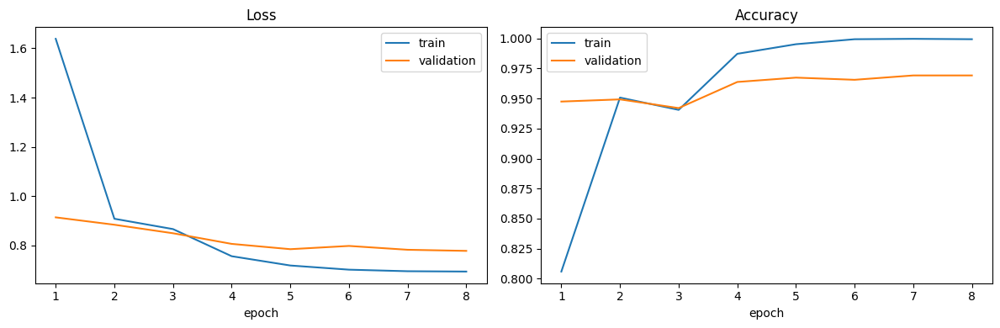

In [10]:
# If training accuracy keeps rising while validation accuracy falls, the model is overfitting
epochs = range(1, len(history) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, [h["train_loss"] for h in history], label="train")
axes[0].plot(epochs, [h["val_loss"] for h in history], label="validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(epochs, [h["train_acc"] for h in history], label="train")
axes[1].plot(epochs, [h["val_acc"] for h in history], label="validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout()
plt.savefig("results/training_curves.png", dpi=120)
plt.show()

## 11. Evaluate the best model on the untouched test set

In [11]:
# Load the checkpoint with the best validation accuracy (not just the last epoch)
model.load_state_dict(torch.load("best_model.pth", map_location=DEVICE))
model.eval()

def predict(model, loader):
    """Return predicted probabilities for every image, plus the true labels."""
    all_probs, all_targets = [], []
    with torch.no_grad():
        for images, targets in loader:
            logits = model(images.to(DEVICE))
            all_probs.append(torch.softmax(logits.float(), dim=1).cpu())
            all_targets.append(targets)
    return torch.cat(all_probs).numpy(), torch.cat(all_targets).numpy()

test_probs, test_targets = predict(model, test_loader)
test_preds = test_probs.argmax(1)

test_acc = (test_preds == test_targets).mean()
# Top-5: is the true breed among the model's 5 most likely guesses?
test_top5 = np.mean([t in np.argsort(p)[-5:] for p, t in zip(test_probs, test_targets)])
print(f"Test accuracy: {test_acc:.3f}  |  Top-5 accuracy: {test_top5:.3f}  |  Images: {len(test_targets)}")

Test accuracy: 0.944  |  Top-5 accuracy: 0.997  |  Images: 3669


## 12. Per-class precision and recall

In [12]:
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

# Precision: when the model says "breed X", how often is it right?
# Recall: of all real breed-X images, how many did the model find?
report = classification_report(test_targets, test_preds, target_names=CLASSES,
                               output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T.loc[CLASSES, ["precision", "recall", "f1-score", "support"]]
per_class.to_csv("results/per_class_metrics.csv")

# Weakest breeds first (lowest recall)
display(per_class.sort_values("recall").round(3))
print(f"Macro precision: {report['macro avg']['precision']:.3f}  |  Macro recall: {report['macro avg']['recall']:.3f}")

,precision,recall,f1-score,support
American Pit Bull Terrier,0.859,0.610,0.713,100.0
Ragdoll,0.830,0.780,0.804,100.0
British Shorthair,0.976,0.820,0.891,100.0
Maine Coon,0.917,0.880,0.898,100.0
Russian Blue,1.000,0.880,0.936,100.0
Staffordshire Bull Terrier,0.725,0.888,0.798,89.0
Birman,0.817,0.890,0.852,100.0
Abyssinian,0.927,0.908,0.918,98.0
Egyptian Mau,0.937,0.918,0.927,97.0
Boxer,0.948,0.929,0.939,99.0


Macro precision: 0.945  |  Macro recall: 0.944


## 13. Confusion matrix

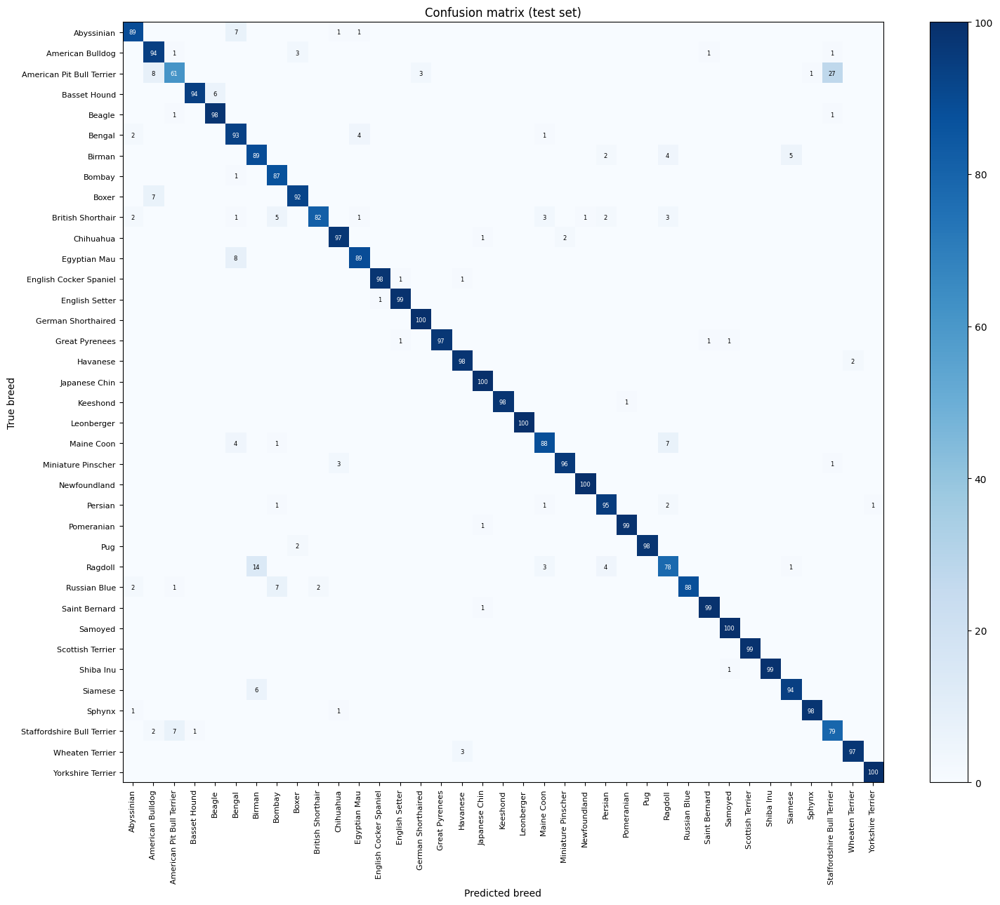

In [13]:
# Rows = true breed, columns = predicted breed; the diagonal holds correct predictions
cm = confusion_matrix(test_targets, test_preds)

fig, ax = plt.subplots(figsize=(15, 13))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASSES)))
ax.set_xticklabels(CLASSES, rotation=90, fontsize=8)
ax.set_yticks(range(len(CLASSES)))
ax.set_yticklabels(CLASSES, fontsize=8)
ax.set_xlabel("Predicted breed")
ax.set_ylabel("True breed")
ax.set_title("Confusion matrix (test set)")

# Write the number in every non-empty cell
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if cm[i, j] > 0:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")

fig.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=130)
plt.show()

## 14. The breeds the model confuses most

In [14]:
# Remove correct predictions (the diagonal), leaving only mistakes
mistakes = cm.copy()
np.fill_diagonal(mistakes, 0)

# Most common "true breed -> predicted breed" mistakes
pairs = sorted(
    [(mistakes[i, j], CLASSES[i], CLASSES[j])
     for i in range(len(CLASSES)) for j in range(len(CLASSES)) if mistakes[i, j] > 0],
    reverse=True,
)
print("Most frequent confusions (true -> predicted):")
for count, true_breed, pred_breed in pairs[:5]:
    print(f"  {true_breed} -> {pred_breed}: {count} images")

# The 3 breeds with the most misclassified images, and what they're mistaken for
print("\nThree most-confused breeds:")
for i in np.argsort(mistakes.sum(1))[::-1][:3]:
    print(f"  {CLASSES[i]}: {mistakes[i].sum()} of {cm[i].sum()} wrong "
          f"(recall {cm[i, i] / cm[i].sum():.2f}), mostly mistaken for {CLASSES[mistakes[i].argmax()]}")

Most frequent confusions (true -> predicted):
  American Pit Bull Terrier -> Staffordshire Bull Terrier: 27 images
  Ragdoll -> Birman: 14 images
  Egyptian Mau -> Bengal: 8 images
  American Pit Bull Terrier -> American Bulldog: 8 images
  Staffordshire Bull Terrier -> American Pit Bull Terrier: 7 images

Three most-confused breeds:
  American Pit Bull Terrier: 39 of 100 wrong (recall 0.61), mostly mistaken for Staffordshire Bull Terrier
  Ragdoll: 22 of 100 wrong (recall 0.78), mostly mistaken for Birman
  British Shorthair: 18 of 100 wrong (recall 0.82), mostly mistaken for Bombay


## 15. Look at the most confident mistakes on the test set

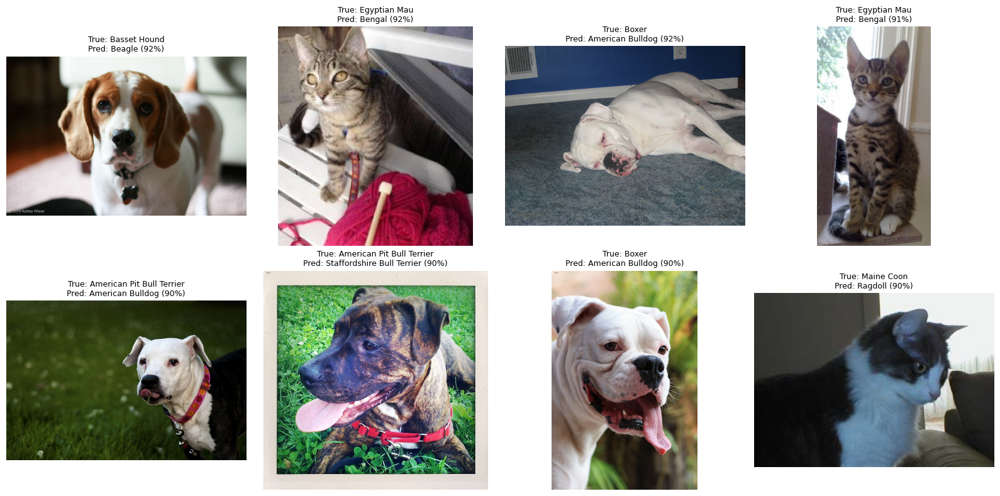

In [15]:
# Wrong predictions the model was most sure about: these reveal real weaknesses
wrong = np.where(test_preds != test_targets)[0]
wrong = wrong[np.argsort(test_probs[wrong].max(1))[::-1]][:8]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, i in zip(axes.flat, wrong):
    image, _ = test_raw[i]                       # original image, without preprocessing
    ax.imshow(image)
    ax.set_title(f"True: {CLASSES[test_targets[i]]}\nPred: {CLASSES[test_preds[i]]} "
                 f"({test_probs[i].max():.0%})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("results/test_mistakes.png", dpi=110)
plt.show()

## 16. Upload my own photos for the generalisation check

In [16]:
# Unzip the uploaded photos (the zip must contain a "my_images" folder)
!unzip -q -o my_images.zip -d .
!ls my_images

 Abyssinian	    'American Pit Bull Terrier'   Beagle
'American Bulldog'  'Basset Hound'


## 17. Run the model on my own photos and compare with the test set

In [17]:
from PIL import Image

def normalise(name):
    """Match folder names to breed names regardless of capitals, spaces, or dashes."""
    return name.lower().replace(" ", "_").replace("-", "_")

name_to_idx = {normalise(c): i for i, c in enumerate(CLASSES)}

# Collect (image path, true label) for every photo
own = []
for folder in sorted(os.listdir("my_images")):
    path = os.path.join("my_images", folder)
    if not os.path.isdir(path):
        continue
    if normalise(folder) not in name_to_idx:
        print("Skipping unknown breed folder:", folder)
        continue
    for file in sorted(os.listdir(path)):
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
            own.append((os.path.join(path, file), name_to_idx[normalise(folder)]))
print("Own images found:", len(own))

# Predict each photo with the same preprocessing as the test set
own_probs = []
with torch.no_grad():
    for path, _ in own:
        x = eval_tf(Image.open(path).convert("RGB")).unsqueeze(0).to(DEVICE)
        own_probs.append(torch.softmax(model(x).float(), dim=1)[0].cpu().numpy())
own_probs = np.array(own_probs)
own_targets = np.array([t for _, t in own])
own_preds = own_probs.argmax(1)

own_acc = (own_preds == own_targets).mean()
own_top5 = np.mean([t in np.argsort(p)[-5:] for p, t in zip(own_probs, own_targets)])

# Fair comparison: test accuracy on ONLY the breeds that appear in my photos
breeds_used = np.unique(own_targets)
mask = np.isin(test_targets, breeds_used)
test_acc_same = (test_preds[mask] == test_targets[mask]).mean()

def wilson_interval(correct, n, z=1.96):
    """95% confidence range for an accuracy: important with only ~30 images."""
    p = correct / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margin = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - margin, centre + margin

low, high = wilson_interval((own_preds == own_targets).sum(), len(own_targets))
print(f"\nTest set accuracy (all 37 breeds):       {test_acc:.3f}")
print(f"Test set accuracy (same {len(breeds_used)} breeds):        {test_acc_same:.3f}")
print(f"My photos accuracy:                      {own_acc:.3f}  (95% range {low:.2f}-{high:.2f})")
print(f"My photos top-5 accuracy:                {own_top5:.3f}")
print(f"Average confidence  test: {test_probs.max(1).mean():.3f}  |  my photos: {own_probs.max(1).mean():.3f}")

# Save every prediction for the README
own_df = pd.DataFrame({
    "file": [p for p, _ in own],
    "true": [CLASSES[t] for t in own_targets],
    "predicted": [CLASSES[p] for p in own_preds],
    "confidence": own_probs.max(1).round(3),
    "correct": own_preds == own_targets,
})
own_df.to_csv("results/own_images_predictions.csv", index=False)
display(own_df)

Own images found: 54

Test set accuracy (all 37 breeds):       0.944
Test set accuracy (same 5 breeds):        0.876
My photos accuracy:                      0.889  (95% range 0.78-0.95)
My photos top-5 accuracy:                0.981
Average confidence  test: 0.842  |  my photos: 0.772


,file,true,predicted,confidence,correct
0,my_images/Abyssinian/images (1).jpg,Abyssinian,Abyssinian,0.870,True
1,my_images/Abyssinian/images (2).jpg,Abyssinian,Abyssinian,0.590,True
2,my_images/Abyssinian/images (3).jpg,Abyssinian,Abyssinian,0.544,True
3,my_images/Abyssinian/images (4).jpg,Abyssinian,Abyssinian,0.924,True
4,my_images/Abyssinian/images (5).jpg,Abyssinian,Abyssinian,0.919,True
5,my_images/Abyssinian/images (6).jpg,Abyssinian,Abyssinian,0.913,True
6,my_images/Abyssinian/images (7).jpg,Abyssinian,Abyssinian,0.867,True
7,my_images/Abyssinian/images.jpg,Abyssinian,Abyssinian,0.865,True
8,my_images/American Bulldog/images (1).jpg,American Bulldog,American Pit Bull Terrier,0.625,False
9,my_images/American Bulldog/images (10).jpg,American Bulldog,American Pit Bull Terrier,0.900,False


## 18. Predictions on my own photos (green = correct, red = wrong)

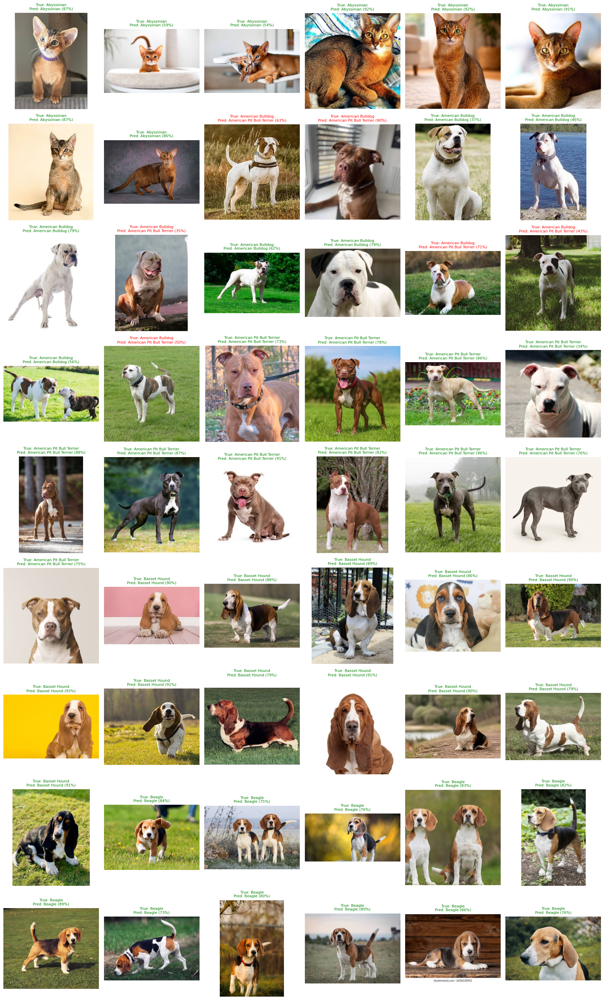

In [18]:
cols = 6
rows = int(np.ceil(len(own) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3.3 * rows))
for ax in axes.flat:
    ax.axis("off")
for ax, (path, true), pred, prob in zip(axes.flat, own, own_preds, own_probs):
    ax.imshow(Image.open(path).convert("RGB"))
    colour = "green" if pred == true else "red"
    ax.set_title(f"True: {CLASSES[true]}\nPred: {CLASSES[pred]} ({prob.max():.0%})", fontsize=8, color=colour)
plt.tight_layout()
plt.savefig("results/own_images_grid.png", dpi=100)
plt.show()

## 19. Failure case analysis with Grad-CAM (where the model looked)

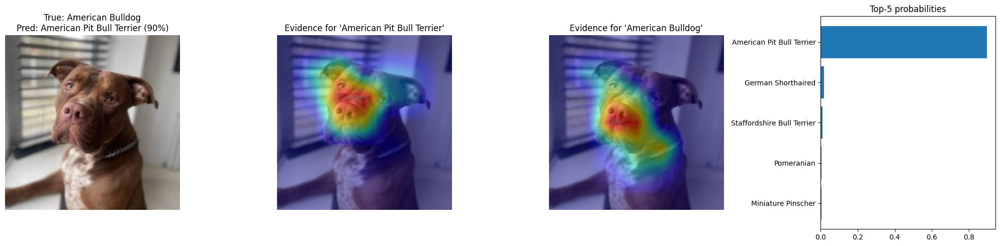

In [19]:
import torch.nn.functional as F

def grad_cam(model, x, class_idx):
    """Heatmap of the image regions that most influenced the prediction for class_idx."""
    store = {}
    layer = model.features[-1]                    # last convolutional stage
    def forward_hook(module, inputs, output):
        store["activations"] = output
        output.register_hook(lambda grad: store.__setitem__("gradients", grad))
    handle = layer.register_forward_hook(forward_hook)

    model.zero_grad()
    logits = model(x)
    logits[0, class_idx].backward()               # how does this class score depend on each region?
    handle.remove()

    acts, grads = store["activations"][0], store["gradients"][0]   # shape: channels x H x W
    weights = grads.mean(dim=(1, 2))              # importance of each channel
    cam = F.relu((weights[:, None, None] * acts).sum(0))
    cam = cam / (cam.max() + 1e-8)
    cam = F.interpolate(cam[None, None], size=x.shape[-2:], mode="bilinear")[0, 0]
    return cam.detach().cpu().numpy()

# Pick a failure: the most confident wrong prediction on my photos
# (if all my photos were correct, use a test-set mistake instead)
own_wrong = np.where(own_preds != own_targets)[0]
if len(own_wrong):
    idx = own_wrong[np.argmax(own_probs[own_wrong].max(1))]
    image = Image.open(own[idx][0]).convert("RGB")
    true_c, probs = own_targets[idx], own_probs[idx]
else:
    idx = wrong[0]
    image, true_c, probs = test_raw[idx][0], test_targets[idx], test_probs[idx]
pred_c = probs.argmax()

x = eval_tf(image).unsqueeze(0).to(DEVICE)
cam_pred = grad_cam(model, x, pred_c)             # what made it say the wrong breed
cam_true = grad_cam(model, x, true_c)             # what it saw for the correct breed

# Undo normalisation so the cropped image displays normally
shown = (x[0].cpu().permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(shown); axes[0].set_title(f"True: {CLASSES[true_c]}\nPred: {CLASSES[pred_c]} ({probs[pred_c]:.0%})")
axes[1].imshow(shown); axes[1].imshow(cam_pred, cmap="jet", alpha=0.45); axes[1].set_title(f"Evidence for '{CLASSES[pred_c]}'")
axes[2].imshow(shown); axes[2].imshow(cam_true, cmap="jet", alpha=0.45); axes[2].set_title(f"Evidence for '{CLASSES[true_c]}'")
top5 = np.argsort(probs)[-5:]
axes[3].barh([CLASSES[i] for i in top5], probs[top5]); axes[3].set_title("Top-5 probabilities")
for ax in axes[:3]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("results/failure_case.png", dpi=110)
plt.show()

## 20. Save a summary of all results

In [20]:
summary = {
    "model": "ConvNeXt-Tiny (ImageNet pretrained), fine-tuned",
    "best_val_accuracy": round(float(best_val_acc), 4),
    "test_accuracy": round(float(test_acc), 4),
    "test_top5_accuracy": round(float(test_top5), 4),
    "test_accuracy_same_breeds_as_own_photos": round(float(test_acc_same), 4),
    "own_photos_count": int(len(own)),
    "own_photos_accuracy": round(float(own_acc), 4),
    "own_photos_accuracy_95ci": [round(float(low), 3), round(float(high), 3)],
    "own_photos_top5_accuracy": round(float(own_top5), 4),
    "top_confusions": [f"{t} -> {p} ({c})" for c, t, p in pairs[:3]],
}
json.dump(summary, open("results/summary.json", "w"), indent=2)
print(json.dumps(summary, indent=2))

{
  "model": "ConvNeXt-Tiny (ImageNet pretrained), fine-tuned",
  "best_val_accuracy": 0.9692,
  "test_accuracy": 0.9436,
  "test_top5_accuracy": 0.997,
  "test_accuracy_same_breeds_as_own_photos": 0.8755,
  "own_photos_count": 54,
  "own_photos_accuracy": 0.8889,
  "own_photos_accuracy_95ci": [
    0.778,
    0.948
  ],
  "own_photos_top5_accuracy": 0.9815,
  "top_confusions": [
    "American Pit Bull Terrier -> Staffordshire Bull Terrier (27)",
    "Ragdoll -> Birman (14)",
    "Egyptian Mau -> Bengal (8)"
  ]
}


In [21]:
# Zip the results folder so it can be downloaded in one click
!zip -q -r results.zip results